## Task 1 – Python environment and library checks

Install the required packages in your terminal (PowerShell, with your virtual environment activated):

```powershell
python -m pip install --upgrade pip
python -m pip install pandas numpy scikit-learn scipy matplotlib seaborn jupyter
```

The next cell checks that the libraries can be imported and prints their versions.

In [1]:
import sys
import pandas as pd
import numpy as np
import scipy
import sklearn
import matplotlib.pyplot as plt
import seaborn as sns

print("Python:", sys.version)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)
print("Scikit-learn:", sklearn.__version__)
print("All required libraries imported successfully.")

Python: 3.13.3 (tags/v3.13.3:6280bb5, Apr  8 2025, 14:47:33) [MSC v.1943 64 bit (AMD64)]
Pandas: 3.1.1
NumPy: 2.5.4
SciPy: 1.18.1
Scikit-learn: 1.9.1
All required libraries imported successfully.


## Task 2 – Download and inspect MovieLens Latest Small

Download the **MovieLens Latest Small** ZIP file from [GroupLens MovieLens](https://grouplens.org/datasets/movielens/latest/), extract it, and put the CSV files in:

```text
project_folder/
├── pre_class_movie_recommendation.ipynb
└── dataset/
    ├── movies.csv
    ├── ratings.csv
    ├── tags.csv
    └── links.csv
```

The next cell searches common locations for the `dataset` folder. If it cannot find the files, edit `DATASET_DIR` manually.

In [2]:
from pathlib import Path

# If automatic detection fails, replace None with your dataset folder path.
# Example on Windows: DATASET_DIR = Path(r"C:\Users\YourName\Downloads\ml-latest-small")
DATASET_DIR = None

if DATASET_DIR is None:
    candidates = [
        Path("dataset"),
        Path("ml-latest-small"),
        Path("../dataset"),
        Path("../ml-latest-small"),
    ]
    found = next((p for p in candidates if (p / "movies.csv").exists()
                  and (p / "ratings.csv").exists()), None)
    if found is None:
        raise FileNotFoundError(
            "Could not find movies.csv and ratings.csv. "
            "Create a dataset folder next to this notebook or set DATASET_DIR manually."
        )
    DATASET_DIR = found

DATASET_DIR = Path(DATASET_DIR)
print("Dataset folder:", DATASET_DIR.resolve())
print("Files:", [p.name for p in DATASET_DIR.glob("*.csv")])

Dataset folder: C:\Users\shivania\Desktop\AI_workshop\weekly_wise_tasks\Week5_Movie_Recommendation_System\dataset
Files: ['movies.csv', 'ratings.csv']


### 2.1 Load the two required CSV files

In [3]:
movies = pd.read_csv(DATASET_DIR / "movies.csv")
ratings = pd.read_csv(DATASET_DIR / "ratings.csv")

print("Movies loaded:", movies.shape)
print("Ratings loaded:", ratings.shape)

Movies loaded: (9742, 3)
Ratings loaded: (100836, 4)


### 2.2 Preview the first five rows

In [4]:
display(movies.head())
display(ratings.head())

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


### Understand the columns

**`movies.csv`**
- `movieId`: unique identifier for each movie.
- `title`: movie title, often including its release year.
- `genres`: genres associated with the movie, separated by `|`.

**`ratings.csv`**
- `userId`: identifier for the user who submitted the rating.
- `movieId`: movie being rated; this connects ratings to `movies.csv`.
- `rating`: user's rating.
- `timestamp`: time at which the rating was submitted (Unix timestamp).

Example 1: if user 1 gives movie 10 a rating of 4.0, the `ratings.csv` row records that interaction.

Example 2: use `movieId` to find the title and genres of movie 10 in `movies.csv`.

### 2.3 Inspect columns, data types, and dataset dimensions

In [5]:
print("MOVIES")
print("Shape:", movies.shape)
print("Columns:", movies.columns.tolist())
movies.info()

print("\\nRATINGS")
print("Shape:", ratings.shape)
print("Columns:", ratings.columns.tolist())
ratings.info()

MOVIES
Shape: (9742, 3)
Columns: ['movieId', 'title', 'genres']
<class 'pandas.DataFrame'>
RangeIndex: 9742 entries, 0 to 9741
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   movieId  9742 non-null   int64
 1   title    9742 non-null   str  
 2   genres   9742 non-null   str  
dtypes: int64(1), str(2)
memory usage: 228.5 KB
\nRATINGS
Shape: (100836, 4)
Columns: ['userId', 'movieId', 'rating', 'timestamp']
<class 'pandas.DataFrame'>
RangeIndex: 100836 entries, 0 to 100835
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   userId     100836 non-null  int64  
 1   movieId    100836 non-null  int64  
 2   rating     100836 non-null  float64
 3   timestamp  100836 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 3.1 MB


### 2.4 Check missing values and duplicate rows

In [6]:
print("Missing values in movies:")
display(movies.isnull().sum())

print("Missing values in ratings:")
display(ratings.isnull().sum())

print("Duplicate movie rows:", movies.duplicated().sum())
print("Duplicate rating rows:", ratings.duplicated().sum())

Missing values in movies:


movieId    0
title      0
genres     0
dtype: int64

Missing values in ratings:


userId       0
movieId      0
rating       0
timestamp    0
dtype: int64

Duplicate movie rows: 0
Duplicate rating rows: 0


### 2.5 Calculate basic statistics

In [7]:
print("Rating statistics:")
display(ratings["rating"].describe())

print("Number of unique users:", ratings["userId"].nunique())
print("Number of unique rated movies:", ratings["movieId"].nunique())
print("Number of movies in movies.csv:", movies["movieId"].nunique())
print("Total rating records:", len(ratings))

Rating statistics:


count    100836.000000
mean          3.501557
std           1.042529
min           0.500000
25%           3.000000
50%           3.500000
75%           4.000000
max           5.000000
Name: rating, dtype: float64

Number of unique users: 610
Number of unique rated movies: 9724
Number of movies in movies.csv: 9742
Total rating records: 100836


### 2.6 Find the most-rated movies

In [8]:
rating_counts = (
    ratings.groupby("movieId")
    .size()
    .reset_index(name="rating_count")
)

most_rated = (
    rating_counts.merge(movies, on="movieId", how="left")
    .sort_values("rating_count", ascending=False)
    .head(10)
)

display(most_rated[["title", "genres", "rating_count"]])

,title,genres,rating_count
314,Forrest Gump (1994),Comedy|Drama|Romance|War,329
277,"Shawshank Redemption, The (1994)",Crime|Drama,317
257,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller,307
510,"Silence of the Lambs, The (1991)",Crime|Horror|Thriller,279
1938,"Matrix, The (1999)",Action|Sci-Fi|Thriller,278
224,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi,251
418,Jurassic Park (1993),Action|Adventure|Sci-Fi|Thriller,238
97,Braveheart (1995),Action|Drama|War,237
507,Terminator 2: Judgment Day (1991),Action|Sci-Fi,224
461,Schindler's List (1993),Drama|War,220


### 2.7 Find average ratings by movie

In [9]:
movie_stats = (
    ratings.groupby("movieId")["rating"]
    .agg(["mean", "count"])
    .reset_index()
    .merge(movies, on="movieId", how="left")
)

# Show movies with at least 20 ratings to avoid over-interpreting
# movies that have only one or two ratings.
top_average_rated = (
    movie_stats[movie_stats["count"] >= 20]
    .sort_values("mean", ascending=False)
    .head(10)
)

display(top_average_rated[["title", "mean", "count"]])

,title,mean,count
840,"Streetcar Named Desire, A (1951)",4.475000,20
277,"Shawshank Redemption, The (1994)",4.429022,317
704,Sunset Blvd. (a.k.a. Sunset Boulevard) (1950),4.333333,27
680,"Philadelphia Story, The (1940)",4.310345,29
905,Lawrence of Arabia (1962),4.300000,45
413,In the Name of the Father (1993),4.300000,25
210,Hoop Dreams (1994),4.293103,29
659,"Godfather, The (1972)",4.289062,192
934,Harold and Maude (1971),4.288462,26
9445,Logan (2017),4.280000,25


### 2.8 Visualize rating distribution

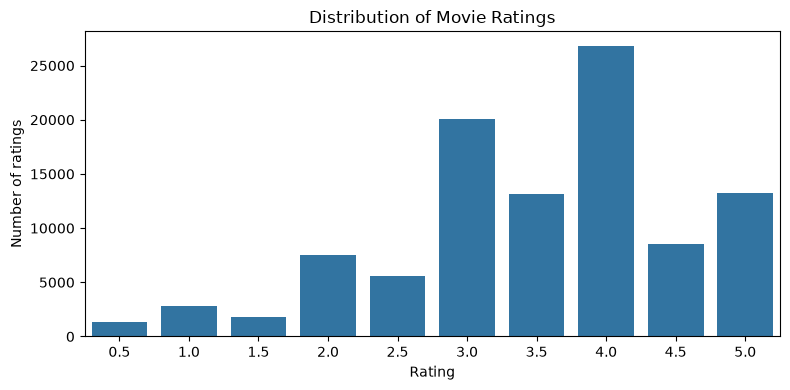

In [10]:
plt.figure(figsize=(8, 4))
sns.countplot(data=ratings, x="rating")
plt.title("Distribution of Movie Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of ratings")
plt.tight_layout()
plt.show()

### 2.9 Explore user activity

count     610.000000
mean      165.304918
std       269.480584
min        20.000000
25%        35.000000
50%        70.500000
75%       168.000000
max      2698.000000
dtype: float64


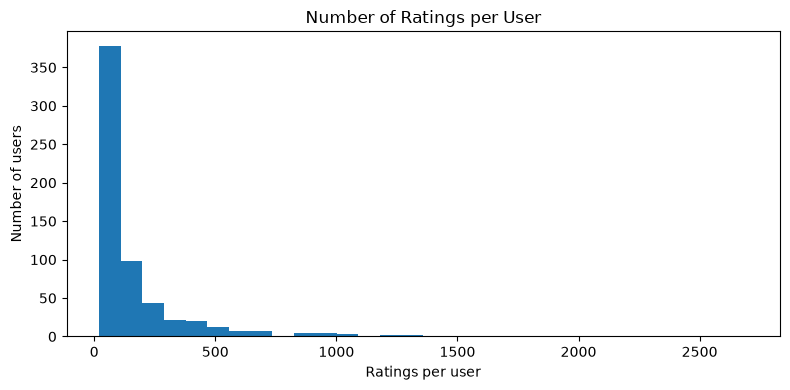

In [11]:
ratings_per_user = ratings.groupby("userId").size()

print(ratings_per_user.describe())

plt.figure(figsize=(8, 4))
plt.hist(ratings_per_user, bins=30)
plt.title("Number of Ratings per User")
plt.xlabel("Ratings per user")
plt.ylabel("Number of users")
plt.tight_layout()
plt.show()

### 2.10 Understand the user–movie interaction matrix and sparsity

In [12]:
# Each row represents a user and each column represents a movie.
# A filled cell means that the user rated that movie.
user_movie = ratings.pivot_table(
    index="userId",
    columns="movieId",
    values="rating"
)

total_possible = user_movie.shape[0] * user_movie.shape[1]
observed = user_movie.notna().sum().sum()
sparsity = 1 - (observed / total_possible)

print("User–movie matrix shape:", user_movie.shape)
print("Observed ratings:", int(observed))
print("Possible user–movie combinations:", int(total_possible))
print(f"Matrix sparsity: {sparsity:.2%}")

User–movie matrix shape: (610, 9724)
Observed ratings: 100836
Possible user–movie combinations: 5931640
Matrix sparsity: 98.30%


**What sparsity means:** most users rate only a small fraction of all movies, so most cells in the user–movie matrix are empty.

Example 1: a user may have rated 30 movies even though the catalogue contains thousands.

Example 2: a movie may have ratings from only a small subset of all users.

This is why recommender systems often use sparse matrix representations rather than storing every possible user–movie value.

## Task 3 – Understand the core concepts

This section is for theory and small practical demonstrations. Read the explanation and run the example cells.

### 3.1 What is a recommendation system?

A recommendation system predicts what a user may prefer and suggests relevant items.

Two common approaches:

1. **Content-Based Filtering:** recommends items with attributes similar to items the user liked.
2. **Collaborative Filtering:** uses patterns in user interactions or ratings to recommend items.

Examples:
- A streaming service recommends another science-fiction movie because you liked science-fiction movies (content-based).
- A streaming service recommends a movie liked by users whose rating patterns resemble yours (collaborative).

### 3.2 Content-based filtering – simple example

In [13]:
# Toy example: movie genres are the item features.
toy_movies = pd.DataFrame({
    "title": ["Space Journey", "Galaxy Mission", "Love in Paris"],
    "genres": ["Sci-Fi|Adventure", "Sci-Fi|Action", "Romance|Drama"]
})
display(toy_movies)

print("If a user likes 'Space Journey', a content-based system may prefer "
      "'Galaxy Mission' because both share the Sci-Fi genre.")

,title,genres
0,Space Journey,Sci-Fi|Adventure
1,Galaxy Mission,Sci-Fi|Action
2,Love in Paris,Romance|Drama


If a user likes 'Space Journey', a content-based system may prefer 'Galaxy Mission' because both share the Sci-Fi genre.


### 3.3 Collaborative filtering

Collaborative filtering uses the behavior of many users.

**User-based collaborative filtering:** find users with similar rating histories, then recommend items they liked.

**Item-based collaborative filtering:** find items that receive similar rating patterns, then recommend items similar to those a user liked.

Example 1 – user-based: User A and User B both rate several movies similarly. User B liked a movie User A has not watched, so it may be recommended to User A.

Example 2 – item-based: users who liked Movie X also tend to like Movie Y. If a user liked Movie X, Movie Y may be recommended.

The following toy table demonstrates the idea:

In [14]:
toy_ratings = pd.DataFrame({
    "User": ["User 1", "User 2", "User 3"],
    "Movie A": [5, 5, 1],
    "Movie B": [4, 4, 2],
    "Movie C": [np.nan, 5, 1]
}).set_index("User")

display(toy_ratings)
print("User 1 and User 2 have similar ratings for Movies A and B. "
      "Movie C could be recommended to User 1 based on User 2's rating.")

,Movie A,Movie B,Movie C
User,,,
User 1,5,4,NaN
User 2,5,4,5.0
User 3,1,2,1.0


User 1 and User 2 have similar ratings for Movies A and B. Movie C could be recommended to User 1 based on User 2's rating.


### 3.4 Cosine similarity

Cosine similarity compares two numerical vectors by measuring the cosine of the angle between them.

\[
\text{cosine similarity}(A,B)=
\frac{A\cdot B}{\|A\|\,\|B\|}
\]

For non-zero vectors:
- `1` means same direction.
- `0` means perpendicular (no directional similarity).
- `-1` means opposite direction.

In recommendation systems, vectors can represent users' ratings of movies or movies' ratings from users. Real implementations must handle missing ratings carefully; a missing rating is not automatically a rating of zero.

### 3.5 Calculate cosine similarity with Scikit-learn

In [15]:
from sklearn.metrics.pairwise import cosine_similarity

# Two users' toy rating vectors for the same three movies.
user_a = np.array([[5, 4, 0]])
user_b = np.array([[5, 4, 5]])
user_c = np.array([[1, 2, 1]])

print("Similarity between A and B:",
      cosine_similarity(user_a, user_b)[0, 0])
print("Similarity between A and C:",
      cosine_similarity(user_a, user_c)[0, 0])

Similarity between A and B: 0.7881701093115123
Similarity between A and C: 0.8288497269823398
